## Figure 1: Vehicle Complaints Show Distinct Patterns of Growth and Decline

This figure compares monthly complaint trends for Ford Escape, Honda Civic, and Toyota Camry using a 12-month rolling average.

**Key Findings:**
- **Ford Escape:** Sustained increase in complaints after 2023.
- **Honda Civic:** Sharp increase in 2024 followed by a significant decline.
- **Toyota Camry:** Moderate fluctuations with multiple complaint peaks.

These differences suggest that temporal features, such as complaint growth rates and rolling averages, may provide useful information for future investigation prediction.

**Caption:** Monthly complaint counts and 12-month rolling averages for three selected models (model years 2018–2020), based on NHTSA filing dates from August 2017 to September 2026. Each subplot uses a different y-axis scale.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[1]
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "complaints_clean.csv"

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())
print(df.columns.tolist())

Shape: (9461, 15)


,complaint_id,make,model,model_year,product_model,filed_date,incident_date,components,crash,fire,number_of_injuries,number_of_deaths,summary,reporting_delay,invalid_incident_date
0,11770133,TOYOTA,CAMRY,2018,CAMRY,2026-10-09,2026-09-29,POWER TRAIN,False,False,0,0,"Total transmission failure at about 107,770 mi...",10.0,False
1,11769969,TOYOTA,CAMRY,2018,CAMRY,2026-10-08,2026-10-06,ENGINE,False,False,0,0,My 2018 Toyota Camry LE went into Limp mode wh...,2.0,False
2,11769124,TOYOTA,CAMRY,2018,CAMRY,2026-10-05,2026-10-03,POWER TRAIN,False,False,0,0,The contact owns a 2018 Toyota Camry. The cont...,2.0,False
3,11768868,TOYOTA,CAMRY,2018,CAMRY,2026-10-04,2026-10-02,FUEL/PROPULSION SYSTEM,False,False,0,0,I am filing a formal complaint regarding a sev...,2.0,False
4,11768335,TOYOTA,CAMRY,2018,CAMRY,2026-10-01,2026-09-29,POWER TRAIN,False,False,0,0,"2018 Toyota Camry approx 126,000 miles. Trans...",2.0,False


['complaint_id', 'make', 'model', 'model_year', 'product_model', 'filed_date', 'incident_date', 'components', 'crash', 'fire', 'number_of_injuries', 'number_of_deaths', 'summary', 'reporting_delay', 'invalid_incident_date']


In [3]:
df["filed_date"] = pd.to_datetime(df["filed_date"], errors="coerce")

print("Earliest filing date:", df["filed_date"].min())
print("Latest filing date:", df["filed_date"].max())

print("\nMissing filing dates:")
print(df["filed_date"].isna().sum())

print("\nComplaints by vehicle model:")
display(
    df.groupby(["make", "model"])
      .size()
      .sort_values(ascending=False)
)

Earliest filing date: 2017-08-04 00:00:00
Latest filing date: 2026-10-12 00:00:00

Missing filing dates:
0

Complaints by vehicle model:


make           model   
FORD           ESCAPE      3943
TOYOTA         CAMRY       1420
HONDA          CIVIC       1170
HYUNDAI        ELANTRA      787
NISSAN         ALTIMA       637
VOLKSWAGEN     TIGUAN       620
AUDI           Q5           284
MERCEDES-BENZ  C-CLASS      255
FORD           F-150        192
BMW            3 SERIES     153
dtype: int64

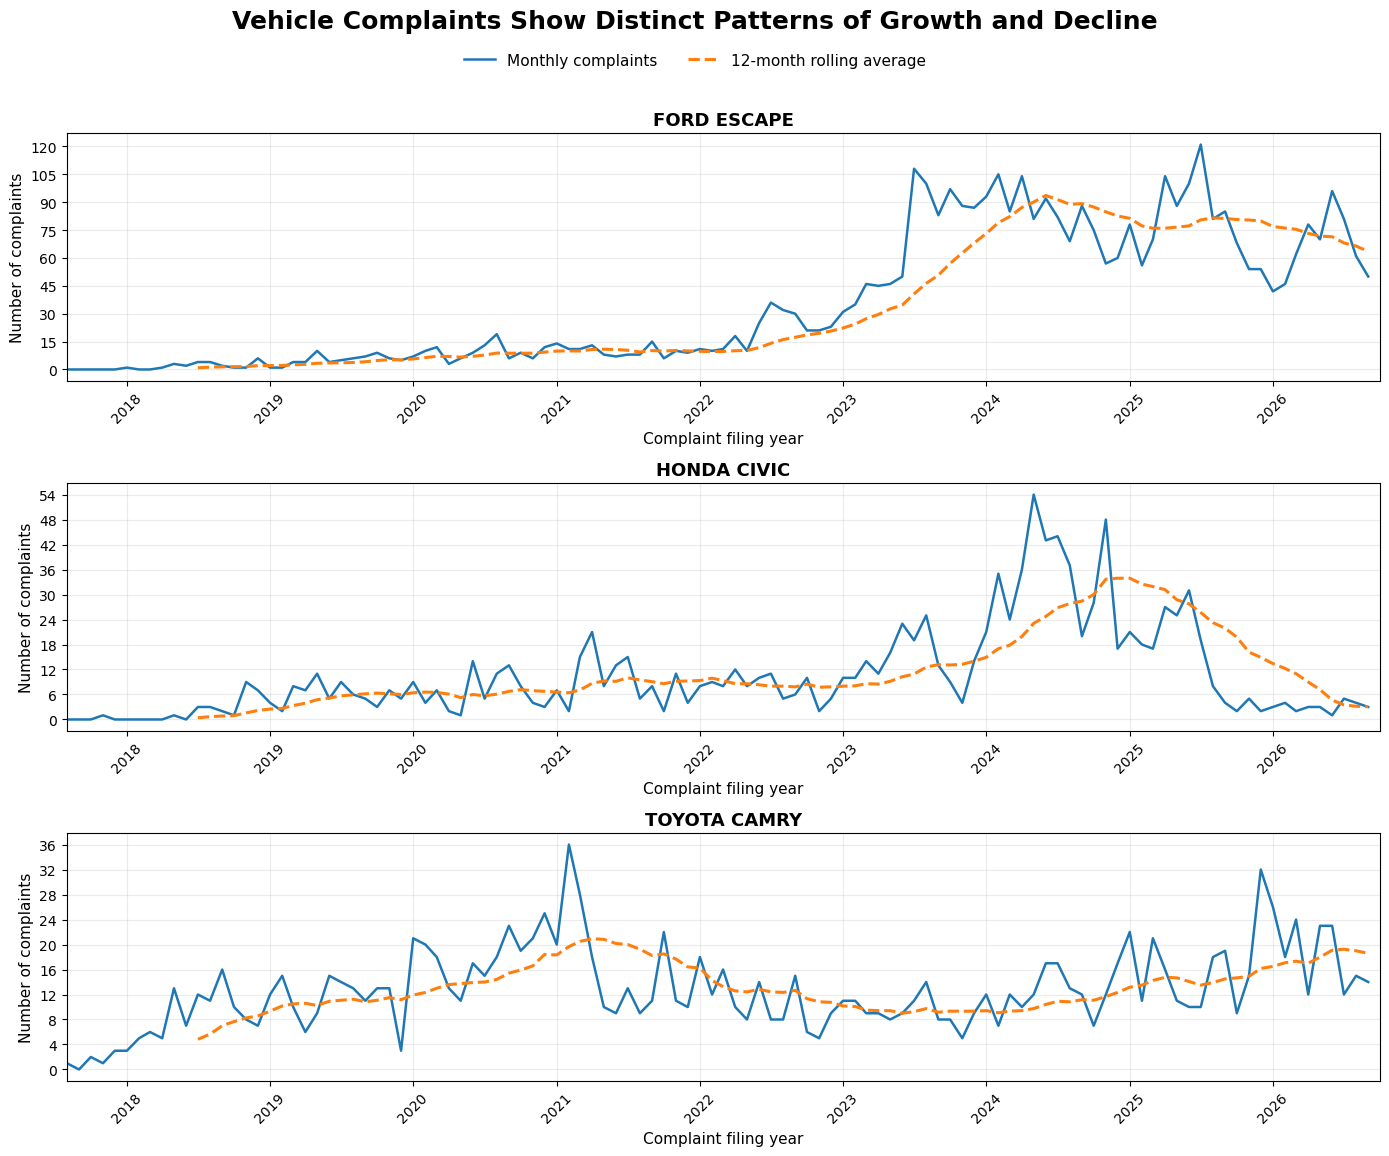

In [15]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator
import pandas as pd

selected_vehicles = [
    "FORD ESCAPE",
    "HONDA CIVIC",
    "TOYOTA CAMRY"
]

selected_monthly = monthly[
    monthly["vehicle"].isin(selected_vehicles)
].copy()

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 12),
    sharex=False
)

for ax, vehicle in zip(axes, selected_vehicles):
    data = selected_monthly[
        selected_monthly["vehicle"] == vehicle
    ].sort_values("filed_month")

    ax.plot(
        data["filed_month"],
        data["complaint_count"],
        linewidth=1.8,
        label="Monthly complaints"
    )

    ax.plot(
        data["filed_month"],
        data["rolling_12m"],
        linewidth=2.2,
        linestyle="--",
        label="12-month rolling average"
    )

    ax.set_title(vehicle, fontsize=13, fontweight="bold")
    ax.set_ylabel("Number of complaints", fontsize=11)
    ax.set_xlabel("Complaint filing year", fontsize=11)

    ax.set_xlim(
        pd.Timestamp("2017-08-01"),
        pd.Timestamp("2026-10-01")
    )

    ax.xaxis.set_major_locator(mdates.YearLocator(1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

    ax.tick_params(axis="x", rotation=45, labelsize=10, labelbottom=True)
    ax.tick_params(axis="y", labelsize=10)

    ax.grid(alpha=0.25)

fig.suptitle(
    "Vehicle Complaints Show Distinct Patterns of Growth and Decline",
    fontsize=18,
    fontweight="bold",
    y=0.98
)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=2,
    frameon=False,
    fontsize=11
)

plt.tight_layout(rect=[0, 0.02, 1, 0.94])

fig.savefig(
    PROJECT_ROOT / "figures" / "complaint_trends_selected.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings

- **Ford Escape:** Complaints increased sharply after 2023 and remained elevated through much of 2024–2025.
- **Honda Civic:** Complaints showed a noticeable spike in 2024, followed by a decline.
- **Toyota Camry:** Complaints fluctuated over time, with multiple peaks but no similarly sustained increase.

These patterns suggest that temporal features, such as complaint growth rates and rolling averages, may provide useful information for future investigation prediction.